# 04 CF, graphs and the hybrid

Builds the skill graph and the prerequisite graph, then tunes the hybrid on validation data: how much weight goes to CF vs content, and how hard the graph pushes back on courses that are too difficult. No API key needed. Saves `results/params.json`.

In [1]:
# Step 0: setup (works in Colab and on a laptop)
import os, sys
from pathlib import Path

# Colab: where the project folder sits in Google Drive
DRIVE_PROJECT = "/content/drive/MyDrive/LearnPath"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path(DRIVE_PROJECT)
else:
    PROJECT_DIR = Path.cwd().parent   # running from the notebooks/ folder

assert (PROJECT_DIR / "src" / "learnpath").exists(), f"Project folder not found: {PROJECT_DIR}"
os.environ["LEARNPATH_DIR"] = str(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/LearnPath


In [2]:
# Step 1: load data
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score
from learnpath import config, experiment as ex, graph, retrieval, plots
from learnpath.hybrid import Recommender
from learnpath.evaluate import evaluate_lists

plots.apply_style()
courses, students, inter, cold, cold_truth = ex.load_data()
print(len(courses), "courses,", len(students), "students,", len(inter), "interactions")

3422 courses, 2000 students, 18219 interactions


## Skill graph

Skills are nodes, and two skills are linked when they appear together on at least two courses. Skills on more than 5% of courses are dropped. Louvain finds the communities and PageRank finds the central skills.

In [3]:
# Step 2: skill graph and communities
SG = graph.build_skill_graph(courses)
print(f"Skill graph: {SG.number_of_nodes():,} skills, {SG.number_of_edges():,} links")
comms = graph.skill_communities(SG)
big = [c for c in comms if len(c) >= 20]
print(f"{len(comms)} communities, {len(big)} with 20+ skills")
pr = nx.pagerank(SG, weight="weight")
for i, c in enumerate(big[:8], 1):
    top = sorted(c, key=lambda s: -pr[s])[:5]
    print(f"  {i}. ({len(c)} skills) " + ", ".join(top))

Skill graph: 2,163 skills, 14,469 links
18 communities, 11 with 20+ skills
  1. (310 skills) language, history, law, english language, thought
  2. (293 skills) finance, market (economics), marketing, innovation, accounting
  3. (286 skills) data analysis, euler's totient function, ordered pair, general statistics, analytics
  4. (280 skills) public health, patient, sustainability, global, biology
  5. (232 skills) security, cloud computing, databases, sql, google cloud platform
  6. (205 skills) leadership, evaluation, education, teaching, experience
  7. (177 skills) energy, mechanical engineering, physics, materials, relative change and difference
  8. (149 skills) web, software, html, software engineering, web development


In [4]:
# Step 3: do the communities match Coursera's own topics?
# Each course gets the community most of its skills belong to, compared with its subdomain
# using normalized mutual information (0 = unrelated, 1 = identical).
skill_comm = {s: i for i, c in enumerate(comms) for s in c}
def course_comm(skills):
    ids = [skill_comm[s] for s in skills if s in skill_comm]
    return max(set(ids), key=ids.count) if ids else -1
cc = courses["skills"].map(course_comm)
mask = cc >= 0
nmi_sub = normalized_mutual_info_score(courses.loc[mask, "subdomain"], cc[mask])
nmi_dom = normalized_mutual_info_score(courses.loc[mask, "domain"], cc[mask])
print(f"NMI with subdomain: {nmi_sub:.2f} | with domain: {nmi_dom:.2f}")
top_pr = sorted(pr, key=pr.get, reverse=True)[:10]
print("Most central skills:", ", ".join(top_pr))

NMI with subdomain: 0.40 | with domain: 0.40
Most central skills: finance, web, language, data analysis, euler's totient function, process, history, market (economics), leadership, ordered pair


The communities overlap with Coursera's topics but don't copy them, since skills like statistics cross topics. The noisy "euler's totient function" tag even ends up near the center, so this graph reflects how Coursera tags courses more than real expertise.

## Prerequisite graph

The data has no real prerequisites, so I infer them. Course A points to B if they share a topic, A is a lower level, and their skills overlap (Jaccard 0.15 or more). Each course keeps its 3 strongest parents. It's rough, but good enough to push down courses a student isn't ready for and to sort the final list into study order.

In [5]:
# Step 4: build the prerequisite graph and show one example path
PG = graph.build_prereq_graph(courses)
with_parents = sum(1 for n in PG if PG.in_degree(n) > 0)
print(f"{PG.number_of_edges():,} prerequisite links; {with_parents:,} courses have at least one parent")
print("No cycles (a valid order exists)?", nx.is_directed_acyclic_graph(PG))

name = dict(zip(courses["course_id"], courses["name"]))
level = dict(zip(courses["course_id"], courses["level"]))
provider = dict(zip(courses["course_id"], courses["provider"]))

def strongest_chain(course_id):
    # walk back from a course, always taking its strongest parent
    chain = [course_id]
    while True:
        parents = sorted(PG.in_edges(chain[0], data="weight"), key=lambda e: (-e[2], e[0]))
        if not parents:
            return chain
        chain.insert(0, parents[0][0])

adv = sorted(n for n in PG if level[n] == "Advanced" and PG.in_degree(n) > 0)
example = max(adv, key=lambda n: (len(strongest_chain(n)), n))
print("\nExample learning path:")
for c in strongest_chain(example):
    print(f"  [{level[c]}] {name[c]}  ({provider[c]})")

2,597 prerequisite links; 1,170 courses have at least one parent
No cycles (a valid order exists)? True

Example learning path:
  [Beginner] Functional Programming Principles in Scala  (École Polytechnique Fédérale de Lausanne)
  [Intermediate] Programming Languages, Part A  (University of Washington)
  [Advanced] Programming Languages, Part C  (University of Washington)


## Tuning (validation only)

- alpha: weight on CF for students with a history (0 = content only, 1 = CF only)
- popularity weight: for new students, how much popularity is mixed into the content score

The test split isn't touched until notebook 06.

In [6]:
# Step 5: tune every space
spaces = retrieval.available_spaces(courses)
print("Retrieval spaces found:", list(spaces))
params = ex.load_params()
params = {k: v for k, v in params.items() if k in spaces}   # drop spaces that are gone
tables = {}
for name_, space in spaces.items():
    p, a_tab, b_tab = ex.tune_space(courses, students, inter, cold, cold_truth, space, PG)
    params[name_] = p
    tables[name_] = (a_tab, b_tab)
    print(name_, p)
ex.save_params(params)
for name_, p in params.items():
    if p["alpha"] >= 1.0:
        print(f"Note: best alpha for {name_} is 1.0, so for students with history its content side adds nothing on validation.")

Retrieval spaces found: ['tfidf', 'sbert', 'openai']
tfidf {'alpha': 0.8, 'cold_pop_weight': 0.5, 'val_recall@5': 0.23}
sbert {'alpha': 1.0, 'cold_pop_weight': 0.5, 'val_recall@5': 0.22125}
openai {'alpha': 1.0, 'cold_pop_weight': 0.5, 'val_recall@5': 0.22125}
Note: best alpha for sbert is 1.0, so for students with history its content side adds nothing on validation.
Note: best alpha for openai is 1.0, so for students with history its content side adds nothing on validation.


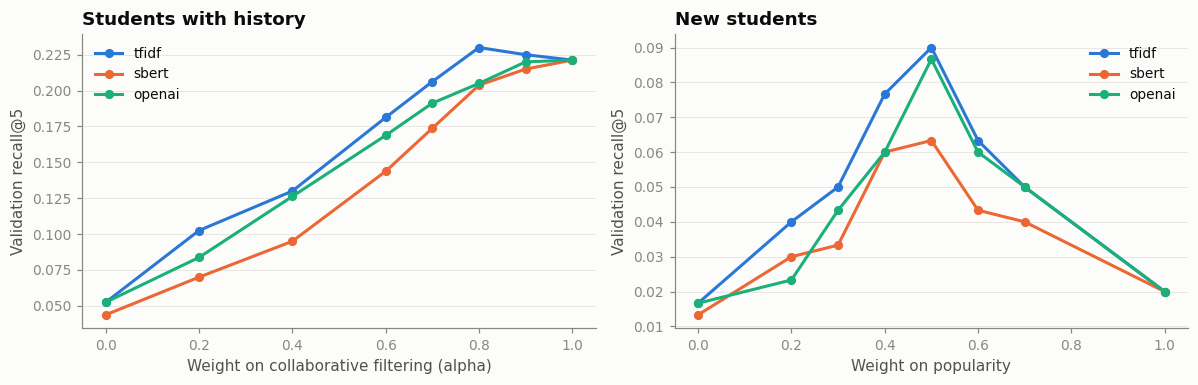

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (name_, (a_tab, b_tab)) in enumerate(tables.items()):
    axes[0].plot(a_tab["alpha"], a_tab["val_recall@5"], marker="o", markersize=5, linewidth=2,
                 color=plots.PALETTE[i], label=name_)
    axes[1].plot(b_tab["cold_pop_weight"], b_tab["val_recall@5"], marker="o", markersize=5, linewidth=2,
                 color=plots.PALETTE[i], label=name_)
axes[0].set_title("Students with history")
axes[0].set_xlabel("Weight on collaborative filtering (alpha)")
axes[0].set_ylabel("Validation recall@5")
axes[1].set_title("New students")
axes[1].set_xlabel("Weight on popularity")
axes[1].set_ylabel("Validation recall@5")
for ax in axes:
    ax.legend()
fig.tight_layout()
plots.save(fig, "04_tuning")
plt.show()

Content alone (alpha 0) is far below anything with CF in it, so behavior wins once a student has a history. For new students, a mix of content and popularity works better than either one.

## Graph strength

The graph lowers courses more than one level above the student, or whose prerequisites they haven't taken. A stronger setting means fewer too-hard picks, but it can also hide courses the student would have taken. I tried four settings on validation data.

In [8]:
# Step 6: graph strength
best = ex.best_space(params, spaces)
fit, hist, truth, truth_done = ex.split_context(inter, "val")
rec = Recommender(courses, spaces[best], PG, fit, alpha=params[best]["alpha"],
                  cold_pop_weight=params[best]["cold_pop_weight"])
sample = students.sample(n=800, random_state=config.SEED)
rows = []
for label, lp, pp, on in [("off", 1, 1, False), ("light", 0.7, 0.9, True),
                          ("medium", 0.5, 0.8, True), ("strong", 0.3, 0.6, True)]:
    rec.level_penalty, rec.prereq_penalty = lp, pp
    lists = {st["student_id"]: rec.recommend(st, hist[st["student_id"]], use_graph=on)
             for st in sample.to_dict("records")}
    s, _ = evaluate_lists(lists, truth, students, courses, rec.checker, hist)
    s_done, _ = evaluate_lists(lists, truth_done, students, courses)
    rows.append({"graph": label, "recall@5": s["recall@5"], "recall@5_finished": s_done["recall@5"],
                 "too_hard": s["too_hard_share"], "prereq_violation": s["prereq_violation_share"]})
rec.level_penalty, rec.prereq_penalty = 0.7, 0.9
strength = pd.DataFrame(rows)
display(strength.round(3))
off, light = strength.iloc[0], strength.iloc[1]
print(f"Light vs off: too-hard picks {off.too_hard:.1%} -> {light.too_hard:.1%}, "
      f"skipped prerequisites {off.prereq_violation:.1%} -> {light.prereq_violation:.1%}")
print(f"Recall cost: {1 - light['recall@5'] / off['recall@5']:.0%} against all next courses, "
      f"{1 - light['recall@5_finished'] / off['recall@5_finished']:.0%} against courses the student finished")

,graph,recall@5,recall@5_finished,too_hard,prereq_violation
0,off,0.230,0.221,0.089,0.168
1,light,0.189,0.200,0.018,0.064
2,medium,0.171,0.178,0.014,0.031
3,strong,0.165,0.173,0.014,0.024


Light vs off: too-hard picks 8.9% -> 1.8%, skipped prerequisites 16.8% -> 6.4%
Recall cost: 18% against all next courses, 10% against courses the student finished


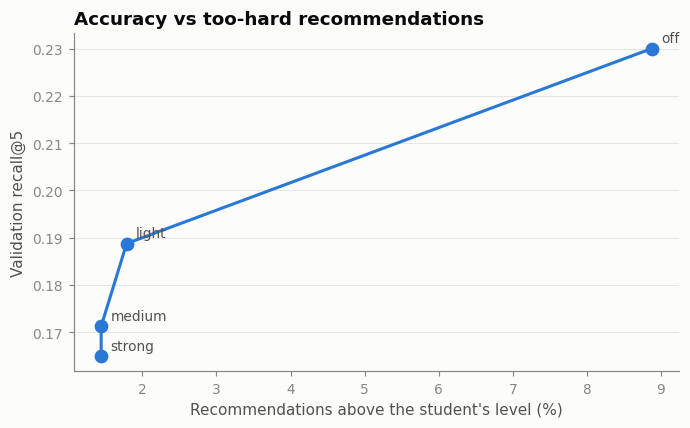

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(strength["too_hard"] * 100, strength["recall@5"], color=plots.PALETTE[0], linewidth=2,
        marker="o", markersize=8)
for _, r in strength.iterrows():
    ax.annotate(r["graph"], (r["too_hard"] * 100, r["recall@5"]), xytext=(6, 4),
                textcoords="offset points", fontsize=9, color=plots.INK_2)
ax.set_title("Accuracy vs too-hard recommendations")
ax.set_xlabel("Recommendations above the student's level (%)")
ax.set_ylabel("Validation recall@5")
fig.tight_layout()
plots.save(fig, "04_graph_tradeoff")
plt.show()

It's a trade-off. Part of the recall the graph loses comes from students who enrolled in courses that were too hard and then dropped them, which is why the cost is smaller when only finished courses count.

I went with the light setting. It removes most too-hard picks, and the stronger settings mostly just cost more recall.